# 第13章 MuJoCo（2）：Walker2d を SAC で歩かせる

**Walker2d** は、[1冊目](ch13_1_hopper.ipynb)の Hopper に、もう1本の脚を足した二本足のロボットです。Hopper と同じく、前後と上下の面の中だけで動き、前（右）へ進むほど報酬が増えます。

この Notebook では、Walker2d を1冊目と同じ **SAC** で学習させます。学習には何時間もかかるので、学習させたモデルを保存し、読み込んで、続きから学習する方法も読みます。

- **前提**: [1冊目](ch13_1_hopper.ipynb)を終えていること（MuJoCo の環境の観測・報酬・終わる条件は、1冊目の3〜4節と6節で読みました）。1冊目の学習を実行していなくても、この Notebook だけで動きます
- **所要の目安**: 実行は CPU で 3 時間半ほど（著者の環境で、Notebook 全体を上から実行して約 207 分。そのうち、4節の Walker2d の学習が約 200 分です）
- **使う装置**: CPU で十分です（この章では GPU を使いません）

> **注記**
> - **出力の出どころ**: この Notebook に残っている出力は、著者の環境（Windows 11、CPU のみ、Gymnasium 1.3.0、MuJoCo 3.17.0、Stable-Baselines3 2.9.0、PyTorch 2.14.1）で 2026-10-29 に実行したものです。各セルの出力がそのまま期待する結果で、直後の「期待する結果」の段落に読み方を書いています。学習にかかる時間は、パソコンによって変わります。
> - **進め方**: セルを上から順に実行します。サンプルのプログラムは、読んで書き写す必要はありません。動かして、読んで、数字を変えて遊んでください。4節の学習はとても長いので、時間のあるときに始めてください。

## 0. 学習目標と完了条件

この Notebook を終えると、次のことができるようになります。

1. Walker2d の観測・行動と、Hopper との違いを、MuJoCo のモデルの中身で説明できる
2. SB3 の SAC で Walker2d を学習させ、成績と歩く様子を見られる
3. 学習させたモデルとリプレイバッファを保存し、読み込んで続きから学習できる

完了条件は、この Notebook を上から最後まで実行して、4節の SAC の **最後の時点のモデル** が、Walker2d-v5 の 100 回の評価で、次の2つを両方満たすことです。

- 報酬の合計の平均が **4000 以上**
- 倒れずに 1,000 ステップ続いた回数が **90 回以上**

Gymnasium 1.3.0 に登録された Walker2d-v5 には、「解けた」の目安（`reward_threshold`）がありません。完了条件は、著者が測った値をもとに上のように決めました（4-2節）。

## 1. 全体像

この Notebook の流れは次のとおりです。

| 節 | すること | 見るもの |
|---|---|---|
| 3節 | Walker2d を知る：観測・行動・MuJoCo のモデル | 体の部分と重さ、でたらめな行動・何もしない場合の成績 |
| 4節 | 動かして楽しむ：SB3 の SAC | 成績、歩く様子 |
| 5節 | 読む：モデルを保存し、続きから学習する | 保存したファイル、読み込んだモデルの成績 |
| 6節 | 学習の経過を見る | 学習中の評価、PPO で試した結果 |
| 7節 | 物理を変えて試す | 重力や胴体の重さを変えたときの成績 |
| 8節 | 遊んでみる | 試してみる設定 |

### コードのセルの標識

コードのセルの直前の段落の始めに、そのセルの扱いを、次の4つの標識で示しています。一つずつ確かめながら読みたいときの目安にしてください。

| 標識 | 意味 |
|---|---|
| **【本質・ここで完結】** | 強化学習の中心のコードです。説明は、直前の段落と、出力のあとの段落で全部です。あとの節で中身のコードを読み直すことはありません（結果を引き合いに出すことはあります） |
| **【本質・○節で振り返る】** | 強化学習の中心のコードですが、ここでは動かして結果を見るだけで大丈夫です。中身は、示した節で読みます |
| **【道具】** | ライブラリの読み込みや、評価の関数を用意するコードなど、学習を支えるコードです。使い方が分かれば十分で、中身のコードはこの先でも説明しません |
| **【可視化】** | 絵やグラフを作るコードです。優先度は低めで、中身は読み飛ばして、出力と、そのあとの読み方だけ見れば十分です |

4-3節の歩く様子は、この Notebook の学習目標2に当たりますが、描くコードの中身は読み飛ばして構いません。読み方は、出力のあとの段落に書いています。

## 2. 準備

> **【道具】** ライブラリの読み込みと、評価に使う関数 `evaluate`・`sb3_policy` の用意です。

`evaluate` と `sb3_policy` は、1冊目の2節と同じ関数で、このあとの節で何度も使います。

In [1]:
import os
import time
from pathlib import Path

import gymnasium as gym
import imageio
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Image
from stable_baselines3 import SAC
from stable_baselines3.common.callbacks import EvalCallback
from stable_baselines3.common.env_util import make_vec_env

FIGURES = Path("figures")
FIGURES.mkdir(exist_ok=True)


# make_env() で作った環境で、方策 policy（観測 → 行動を返す関数）で episodes 回遊ばせる
# 報酬の合計の平均と標準偏差、エピソードの終わり方の回数、最後の時点の胴体の x 座標の平均を返す
def evaluate(policy, make_env, episodes=100, seed=100):
    env = make_env()
    totals = np.zeros(episodes)
    distances = np.zeros(episodes)
    endings = {"倒れた": 0, "続いた": 0}
    for i in range(episodes):
        observation, info = env.reset(seed=seed + i)
        while True:
            observation, reward, terminated, truncated, info = env.step(policy(observation))
            totals[i] += reward
            if terminated or truncated:
                break
        distances[i] = info.get("x_position", 0.0)
        endings["倒れた" if terminated else "続いた"] += 1
    return totals.mean(), totals.std(), endings, distances.mean()


# SB3 のモデルで、決まった行動を選ぶ方策を返す
def sb3_policy(model):
    return lambda observation: model.predict(observation, deterministic=True)[0]

> **【可視化】** 優先度は低めです。エピソードの絵を集める関数を用意するコードです（このセルに出力は無く、使うのは4-3節です。出力を残した実行のあとに、準備のセルから分けたため、実行番号はありません）。

`record_episode` は、1冊目の2節と同じ関数です。

In [ ]:
# 方策 policy で1エピソード遊ばせ、every ステップごとの (ステップ数, 絵) の一覧を返す
# （絵は Gymnasium と MuJoCo の描画）
def record_episode(policy, env_id, seed, every):
    env = gym.make(env_id, render_mode="rgb_array", width=320, height=320)
    observation, info = env.reset(seed=seed)
    shots = [(0, env.render())]
    steps = 0
    while True:
        observation, reward, terminated, truncated, info = env.step(policy(observation))
        steps += 1
        if steps % every == 0 or terminated or truncated:
            shots.append((steps, env.render()))
        if terminated or truncated:
            return shots

## 3. Walker2d を知る：観測・行動・MuJoCo のモデル

### 3-1. 観測・行動と、体の部分

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

観測と行動の空間と、MuJoCo のモデルの中の関節と体の部分を見ます。

In [2]:
make_walker = lambda: gym.make("Walker2d-v5")
env = make_walker()
observation, info = env.reset(seed=0)
m = env.unwrapped.model
print("観測の空間:", env.observation_space.shape, "行動の空間:", env.action_space)
print("関節の名前:", [m.joint(i).name for i in range(m.njnt)])
for i in range(1, m.nbody):  # 0 番は地面などをまとめた world
    print(f"  体の部分 {i}: {m.body(i).name:10s} 重さ {m.body_mass[i]:.2f} kg")
print("1ステップは", env.unwrapped.dt,
      "秒、打ち切りのステップ数:", env.spec.max_episode_steps,
      "、「解けた」の目安:", env.spec.reward_threshold)

観測の空間: (17,) 行動の空間: Box(-1.0, 1.0, (6,), float32)
関節の名前: ['rootx', 'rootz', 'rooty', 'thigh_joint', 'leg_joint', 'foot_joint', 'thigh_left_joint', 'leg_left_joint', 'foot_left_joint']
  体の部分 1: torso      重さ 3.67 kg
  体の部分 2: thigh      重さ 4.06 kg
  体の部分 3: leg        重さ 2.78 kg
  体の部分 4: foot       重さ 3.17 kg
  体の部分 5: thigh_left 重さ 4.06 kg
  体の部分 6: leg_left   重さ 2.78 kg
  体の部分 7: foot_left  重さ 3.17 kg
1ステップは 0.008 秒、打ち切りのステップ数: 1000 、「解けた」の目安: None


**期待する結果**（上の出力の読み方）: 観測は 17 個の値、行動は -1〜1 の6つの値の組（`Box(-1.0, 1.0, (6,), float32)`）です。関節は9つで、最初の3つ（`rootx`・`rootz`・`rooty`）は胴体の前後の位置・高さ・傾き、残りの6つは右の脚（`thigh_joint`・`leg_joint`・`foot_joint`）と左の脚（名前の最後が `_left`）の、もも・すね・足のつけ根の関節です。体の部分は7つで、胴体が 3.67 kg、もも・すね・足は、左右とも 4.06 kg・2.78 kg・3.17 kg です。1ステップは 0.008 秒、打ち切りは 1,000 ステップで、「解けた」の目安は登録されていません（`None`）。

観測の 17 個の値は、Hopper の 11 個に、左の脚の3つの関節の角度と角速度を足したものです（Gymnasium 1.3.0 の `gymnasium/envs/mujoco/walker2d_v5.py` の環境の説明と `_get_obs` の処理）。

| 番号 | 値 |
|---|---|
| 0〜1 | 胴体の高さ（z 座標）、胴体の傾きの角度 |
| 2〜4 | 右の脚のもも・すね・足のつけ根の関節の角度 |
| 5〜7 | 左の脚のもも・すね・足のつけ根の関節の角度 |
| 8〜16 | 胴体の前後の速さ、上下の速さ、傾きの角速度、6つの関節の角速度（-10〜10 に切り詰めた値） |

- 行動（6つの値、どれも -1〜1）: 6つの関節のモーターの力です
- 報酬: Hopper と同じく、「前へ進んだ分」＋「倒れずにいた分（健康なら 1）」−「モーターの力の分（0.001 × 行動の値の2乗の和）」です（`walker2d_v5.py` の `_get_rew`）
- 終わる条件: 胴体の高さが 0.8〜2.0 の間、胴体の傾きの角度が −1〜1 ラジアンの間にあれば「健康」で、そうでなくなると終わります（`is_healthy`）。Hopper（高さ 0.7 より上、角度 −0.2〜0.2 ラジアン）より、傾きの許される幅が広くなっています。終わらなければ 1,000 ステップで打ち切られます

### 3-2. でたらめな行動と、何もしない場合

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

でたらめな行動と、何もしない行動（6つの値を 0 にする）で、それぞれ 100 回遊ばせます。

In [3]:
env = make_walker()
env.action_space.seed(0)
for name, policy in [
        ("でたらめな行動", lambda observation: env.action_space.sample()),
        ("何もしない", lambda observation: np.zeros(6, dtype=np.float32))]:
    mean, std, endings, distance = evaluate(policy, make_walker)
    print(f"{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
          f"最後の x 座標の平均 {distance:.2f} m")

でたらめな行動: 報酬の合計の平均 1.7、標準偏差 7.5、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 -0.15 m


何もしない: 報酬の合計の平均 96.5、標準偏差 9.8、{'倒れた': 100, '続いた': 0}、最後の x 座標の平均 -0.15 m


**期待する結果**（上の出力の読み方）: でたらめな行動は平均 1.7（標準偏差 7.5）、何もしない場合は平均 96.5（標準偏差 9.8）で、どちらも 100 回とも倒れました。最後の x 座標の平均は、どちらも -0.15 m で、前へは進んでいません。

## 4. 動かして楽しむ：SB3 の SAC

### 4-1. 学習させる

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です（SAC の仕組みは第10章の6節で読みました）。

ハイパーパラメータは、1冊目の5節の Hopper と同じ、**RL Zoo** の MuJoCo の環境に共通の SAC の値です（`sac.yml` の項目は旧版の `Walker2d-v4` 用で、その値を Walker2d-v5 に使います。1,000,000 ステップ、`learning_starts` 10,000、ほかは SB3 の既定値。出典は末尾）。学習中の様子を見るために、`EvalCallback` で、50,000 ステップごとに 5 回遊ばせて評価します。著者の環境では 11,994 秒（約 200 分）かかりました。

In [4]:
seed = 0
train_env = make_vec_env("Walker2d-v5", n_envs=1, seed=seed)
eval_env = make_vec_env("Walker2d-v5", n_envs=1, seed=1000 + seed)
callback = EvalCallback(eval_env, n_eval_episodes=5, eval_freq=50_000,
                        log_path="checkpoints/sac_walker", verbose=0)
model = SAC("MlpPolicy", train_env, learning_starts=10_000,
            seed=seed, device="cpu", tensorboard_log="logs")
start = time.perf_counter()
model.learn(total_timesteps=1_000_000, callback=callback, tb_log_name="sac_walker")
print(f"学習にかかった時間: {time.perf_counter() - start:.0f} 秒")
print("50,000 ステップごとの評価（5 回の平均）:",
      np.round(np.mean(callback.evaluations_results, axis=1), 1))

学習にかかった時間: 11994 秒
50,000 ステップごとの評価（5 回の平均）: [ 234.8  353.5  530.6  769.4  933.9 2275.1 1509.2  853.6 2433.9 4241.7
 4285.3 4304.  3343.5 4481.3 4365.3 4494.7 4663.7 4729.8 4604.8 4608.1]


**期待する結果**（上の出力の読み方）: 学習には 11,994 秒（約 200 分）かかりました。50,000 ステップごとの評価（5 回の平均）は、1 回目の 234.8 から上がり、300,000 ステップで 2275.1 になったあと、400,000 ステップで 853.6 に下がりました。500,000 ステップで 4241.7 になってからは、650,000 ステップの 3343.5 を除いて、4241.7〜4729.8 の間です。

`seed=0`（学習）と `seed=1000`（学習中の評価の環境）を固定しています。`checkpoints` フォルダと `logs` フォルダは、学習のたびに作り直せるものなので、Git の管理から外しています。学習の記録を TensorBoard で見る手順は、[第1章](../ch01_first_training/ch01_first_training.ipynb)の6-2節と同じです（フォルダを `chapters\ch13_mujoco\logs` にします）。

### 4-2. 成績を測る

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

最後の時点のモデルを、100 回評価します。

In [5]:
mean, std, endings, distance = evaluate(sb3_policy(model), make_walker)
print(f"最後の時点のモデル: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
      f"最後の x 座標の平均 {distance:.2f} m")

最後の時点のモデル: 報酬の合計の平均 4670.0、標準偏差 57.3、{'倒れた': 0, '続いた': 100}、最後の x 座標の平均 29.38 m


**期待する結果**（上の出力の読み方）: 最後の時点のモデルは、100 回の平均が 4670.0（標準偏差 57.3）で、100 回とも倒れずに 1,000 ステップ続きました。最後の x 座標の平均は 29.38 m です。完了条件（平均 4000 以上、続いた回数 90 回以上）を両方満たしています。

この節の値は、著者が別に動かした試作のスクリプト（同じ設定と seed）で測った値と同じでした。この章では、学習の seed を 0 だけで測りました。学習には長い時間がかかるので、seed を変えた成績は測っていません。seed を変えると、成績が変わる場合があります（第7章・第11章では、seed によって成績が変わりました）。

### 4-3. 歩く様子を見る

> **【可視化】** 優先度は低めです。絵を集めて GIF に保存するコードです。

最後の時点のモデルで1エピソード遊ばせ、10 ステップごとの絵を GIF に保存します。Walker2d の1ステップは 0.008 秒（1 秒に 125 ステップ。`render_fps`）なので、1 枚を 80 ミリ秒で表示すると、ほぼその速さです。画面は、胴体に合わせて動きます。

エピソードのステップ数: 1000


GIF の枚数: 101


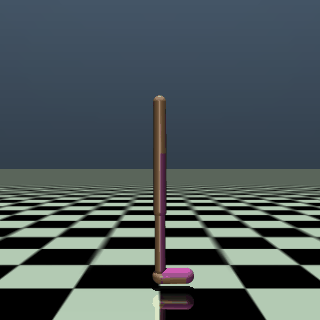

In [6]:
shots = record_episode(sb3_policy(model), "Walker2d-v5", seed=0, every=10)
print("エピソードのステップ数:", shots[-1][0])
imageio.v3.imwrite(FIGURES / "ch13_sac_walker2d.gif",
                   [frame for _, frame in shots], duration=80, loop=0)
print("GIF の枚数:", len(shots))
Image(filename=FIGURES / "ch13_sac_walker2d.gif")

**期待する結果**（上の出力の読み方）: このエピソードは、倒れずに打ち切りの 1,000 ステップまで続きました。出力の「GIF の枚数: 101」は、最初の絵と、10 ステップごとの絵 100 枚を合わせた数です（最後の 1,000 ステップ目は 10 の倍数なので、10 ステップごとの絵に入っています）。

**期待する結果**（VS Code などで実行した場合）: 上の出力は、上のエピソードの GIF です。ロボットは、2本の脚をそろえてまっすぐ立った姿勢から歩き出し、胴体を進む向き（右）へ少し傾けたまま、2本の脚を交互に前へ出して進みます。最後の 1,000 ステップまで倒れません。

> **【可視化】** 優先度は低めです。コマ送りの図を作るコードです。

GitHub でこの Notebook を読んでいる場合、上の出力の GIF の動きは見られません（著者が、private だった 2026-10-01 に第0章で、public にした後の 2026-10-10 に第3〜5章で確かめました）。GIF は、この章のフォルダの [README.md](README.md) でも見られます。Notebook の中でも見られるように、次のセルで、同じエピソードのコマ送りの図を作ります。

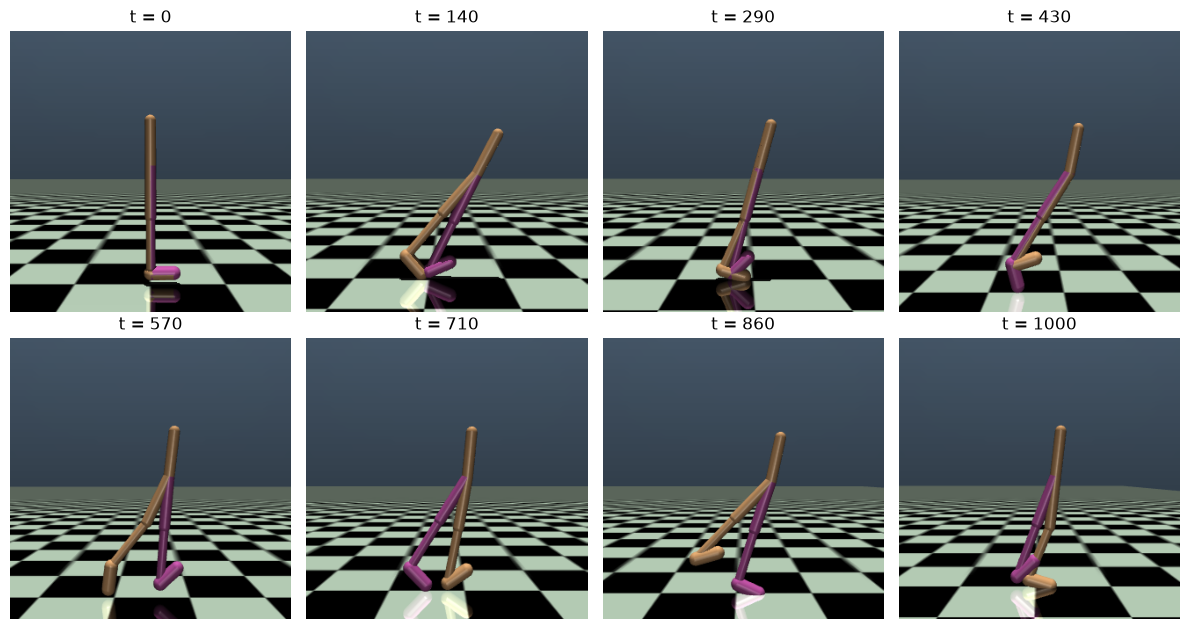

In [7]:
picks = np.linspace(0, len(shots) - 1, 8).round().astype(int)  # 等間隔に 8 枚選ぶ
fig, axes = plt.subplots(2, 4, figsize=(12, 6.4))
for ax, i in zip(axes.flat, picks):
    t, frame = shots[i]
    ax.imshow(frame)
    ax.set_title(f"t = {t}")
    ax.axis("off")
fig.tight_layout()
fig.savefig(FIGURES / "ch13_sac_walker2d_frames.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 上のエピソードから、等間隔に選んだ 8 枚（t = 0、140、290、430、570、710、860、1000）です。t = 0 では、2本の脚をそろえてまっすぐ立っています。t = 140 から t = 1000 までは、胴体を右（進む向き）へ少し傾けた姿勢で、2本の脚を前後に開いたり、片方の脚の膝を曲げて持ち上げたりしています。どの絵でも、胴体は倒れていません。

## 5. 読む：モデルを保存し、続きから学習する

### 5-1. モデルとリプレイバッファを保存する

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

4節の学習には何時間もかかりました。学習させたモデルは、ファイルに保存しておけば、あとで読み込んで評価したり、続きから学習したりできます。SAC のような方策オフの手法では、モデル（ネットワークの重みと設定）のほかに、リプレイバッファ（集めた経験）も、続きから学習するのに使います。SB3 では、2つを別々のファイルに保存します。

In [8]:
model.save("checkpoints/sac_walker_final")
model.save_replay_buffer("checkpoints/sac_walker_buffer")
for path in ["checkpoints/sac_walker_final.zip",
             "checkpoints/sac_walker_buffer.pkl"]:
    print(f"{path}: {os.path.getsize(path) / 1e6:.1f} MB")
print("リプレイバッファに入っている経験の数:", model.replay_buffer.size())

checkpoints/sac_walker_final.zip: 3.2 MB
checkpoints/sac_walker_buffer.pkl: 308.0 MB
リプレイバッファに入っている経験の数: 1000000


**期待する結果**（上の出力の読み方）: モデルのファイル（`.zip`）は 3.2 MB、リプレイバッファのファイル（`.pkl`）は 308.0 MB です。リプレイバッファには 1,000,000 個の経験が入っていて、学習の 1,000,000 ステップの経験が、`buffer_size` の既定値（1,000,000）いっぱいまで、すべて残っています。

- `model.save` は、ネットワークの重みと、ハイパーパラメータなどの設定を、zip 形式の1つのファイルにまとめます。リプレイバッファは入りません（SB3 2.9.0 の `stable_baselines3/common/base_class.py` の `save` は、`_excluded_save_params` に並べた `replay_buffer` などを保存から外します。ソースのコメントには、大きいためと書かれています）
- `model.save_replay_buffer` は、リプレイバッファを pickle 形式で保存します（`off_policy_algorithm.py`）

### 5-2. 読み込んで評価し、続きから学習する

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

保存したファイルを読み込んで、新しいモデルを作ります。読み込んだモデルを 10 回評価して、4節のモデルと比べたあと、リプレイバッファも読み込んで、10,000 ステップだけ続きから学習させます。

In [9]:
loaded = SAC.load("checkpoints/sac_walker_final",
                  env=make_vec_env("Walker2d-v5", n_envs=1, seed=1), device="cpu")
print("読み込んだモデルの学習したステップ数:", loaded.num_timesteps)
for name, m in [("4節のモデル", model), ("読み込んだモデル", loaded)]:
    mean, std, endings, distance = evaluate(sb3_policy(m), make_walker, episodes=10)
    print(f"{name}（10 回）: 報酬の合計の平均 {mean:.1f}、{endings}")

loaded.load_replay_buffer("checkpoints/sac_walker_buffer")
print("読み込んだリプレイバッファの経験の数:", loaded.replay_buffer.size())
start = time.perf_counter()
loaded.learn(total_timesteps=10_000, reset_num_timesteps=False)
print(f"続きの学習にかかった時間: {time.perf_counter() - start:.0f} 秒、"
      f"学習したステップ数: {loaded.num_timesteps}")

読み込んだモデルの学習したステップ数: 1000000


4節のモデル（10 回）: 報酬の合計の平均 4654.6、{'倒れた': 0, '続いた': 10}


読み込んだモデル（10 回）: 報酬の合計の平均 4654.6、{'倒れた': 0, '続いた': 10}


読み込んだリプレイバッファの経験の数: 1000000


続きの学習にかかった時間: 112 秒、学習したステップ数: 1010000


**期待する結果**（上の出力の読み方）: 読み込んだモデルの学習したステップ数は 1,000,000 で、4節のモデルと同じです。10 回の評価は、4節のモデルも読み込んだモデルも平均 4654.6 で、10 回とも倒れずに続きました（同じ重みで、同じ始まり方の 10 回なので、同じ値です）。読み込んだリプレイバッファの経験の数は 1,000,000 です。続きの 10,000 ステップの学習は 112 秒で、学習したステップ数は 1,010,000 になりました。

- `SAC.load` は、保存した設定でモデルを作り直し、重みを読み込みます。`env` には、学習を続けるときに使う環境を渡します
- `learn(..., reset_num_timesteps=False)` にすると、学習したステップ数を 0 に戻さずに、続きから数えます（`base_class.py` の `_setup_learn`）。SAC の `learning_starts` も、通算のステップ数と比べるので、続きの学習では、でたらめな行動で集め直すことはありません

### 5-3. 学習の途中で保存しておく

学習が途中で止まると、それまでの学習は無駄になります。SB3 の `CheckpointCallback` を使うと、決めたステップ数ごとに、モデル（と、`save_replay_buffer=True` ならリプレイバッファ）を保存できます（`stable_baselines3/common/callbacks.py`）。4-1節の学習のセルなら、次のように足します。

```python
from stable_baselines3.common.callbacks import CheckpointCallback

checkpoint = CheckpointCallback(
    save_freq=100_000, save_path="checkpoints/sac_walker_ckpt",
    name_prefix="sac_walker", save_replay_buffer=True)
model.learn(total_timesteps=1_000_000, callback=[callback, checkpoint],
            tb_log_name="sac_walker")
```

保存したファイルの名前は、`sac_walker_100000_steps.zip`・`sac_walker_replay_buffer_100000_steps.pkl` のように、その時点のステップ数が入ります。止まったあとは、一番新しいファイルを 5-2節と同じように読み込み、残りのステップ数を `learn(..., reset_num_timesteps=False)` で学習させます。保存のたびに別のファイルになるので、リプレイバッファを毎回保存すると、5-1節の大きさのファイルが、保存の回数だけたまります。

## 6. 学習の経過を見る

### 6-1. 学習中の評価

> **【可視化】** 優先度は低めです。学習中の評価を図に描くコードです。

4節の、学習中の評価（5 回の平均）を並べます。

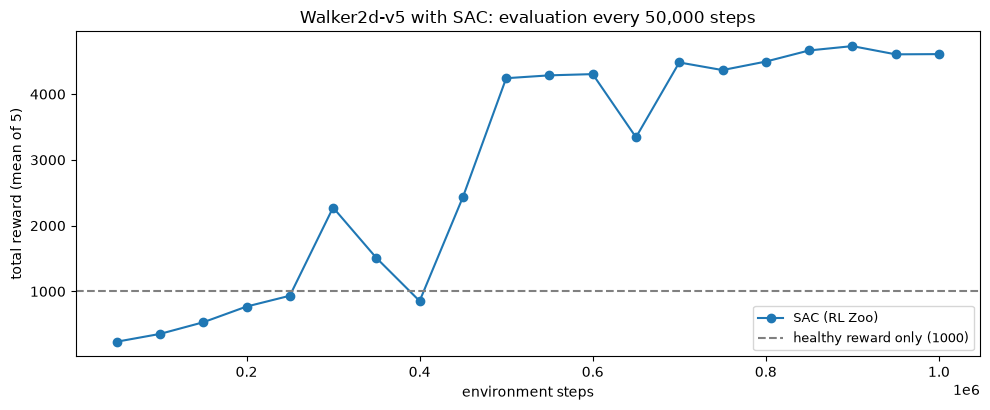

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.plot(callback.evaluations_timesteps,
        np.mean(callback.evaluations_results, axis=1), "o-",
        color="tab:blue", label="SAC (RL Zoo)")
ax.axhline(1000, color="gray", linestyle="--", label="healthy reward only (1000)")
ax.set_xlabel("environment steps")
ax.set_ylabel("total reward (mean of 5)")
ax.set_title("Walker2d-v5 with SAC: evaluation every 50,000 steps")
ax.legend(loc="lower right", fontsize=9)
fig.tight_layout()
fig.savefig(FIGURES / "ch13_walker2d_learning_curve.png", dpi=80)
plt.show()

**期待する結果**（上の出力の読み方）: 青い丸は、始めの 234.8 から上がり、300,000 ステップで 2275.1 になったあと、400,000 ステップで 853.6 に下がりました。500,000 ステップで 4241.7 に上がってからは、650,000 ステップの 3343.5 を除いて、4241.7〜4729.8 の間にあります。灰色の破線は、倒れずにいた分だけで 1,000 ステップ続いたときの合計 1000 です。

### 6-2. PPO で試した結果（参考）

この章の手法を決める前に、著者は、PPO でも Walker2d を学習させました。RL Zoo v2.9.0 の PPO の `Walker2d-v4` 用の調整済みの値を Walker2d-v5 に使い（1,000,000 ステップ。第12章と同じ `VecNormalize` で観測と報酬を正規化する設定）、学習の seed は 0 だけです。この Notebook では動かしていません。評価は、この Notebook の `evaluate` と同じ 100 回、最後の時点のモデルです。

| 手法 | 報酬の合計の平均 | 標準偏差 | 倒れた | 続いた | 最後の x 座標の平均 | 著者の環境での学習の時間 |
|---|---|---|---|---|---|---|
| SAC（4節のモデル） | 4670.0 | 57.3 | 0 回 | 100 回 | 29.38 m | 約 200 分 |
| PPO（著者の試作） | 3702.0 | 920.7 | 45 回 | 55 回 | 22.92 m | 約 49 分 |

- この設定と seed では、PPO の最後の時点のモデルは、SAC より平均が低く、100 回のうち 45 回倒れました
- PPO の学習中の評価（50,000 ステップごとに 5 回の平均）は、900,000 ステップで 4218.2、最後の 1,000,000 ステップで 4118.2 でした。5 回の評価では、100 回の評価よりも高い値でした
- 学習の時間は、PPO のほうがずっと短く済みました

1冊目の6-3節の Hopper の結果と合わせて、著者は、この章では SAC を使うことにしました。seed 1 つずつの比較なので、どちらの手法が Walker2d に向いているかは、これだけでは言えません。RL Zoo が公開している学習済みのエージェントの成績（v2.9.0 の `benchmark.md`。それぞれ1回の学習で、環境は旧版の Walker2d-v3）では、平均は PPO が 3478.8、SAC が 3863.2 です。

## 7. 物理を変えて試す

> **【本質・ここで完結】** 説明は、ここと出力のあとの段落で全部です。

1冊目の8節と同じく、重力を半分・1.5 倍にした場合と、胴体を 2 倍に重くした場合に、4節のモデルを学習し直さずに、そのまま 100 回評価します。

In [11]:
# 重力を gravity 倍、胴体の重さを torso 倍にした Walker2d を作る関数を返す
def make_changed_walker(gravity=1.0, torso=1.0):
    def make_env():
        env = gym.make("Walker2d-v5")
        m = env.unwrapped.model
        m.opt.gravity[2] *= gravity
        m.body_mass[m.body("torso").id] *= torso
        return env
    return make_env


for name, kwargs in [("元のまま", {}), ("重力 0.5 倍", dict(gravity=0.5)),
                     ("重力 1.5 倍", dict(gravity=1.5)), ("胴体 2 倍", dict(torso=2.0))]:
    mean, std, endings, distance = evaluate(
        sb3_policy(model), make_changed_walker(**kwargs))
    print(f"{name}: 報酬の合計の平均 {mean:.1f}、標準偏差 {std:.1f}、{endings}、"
          f"最後の x 座標の平均 {distance:.2f} m")

元のまま: 報酬の合計の平均 4670.0、標準偏差 57.3、{'倒れた': 0, '続いた': 100}、最後の x 座標の平均 29.38 m


重力 0.5 倍: 報酬の合計の平均 274.5、標準偏差 635.6、{'倒れた': 97, '続いた': 3}、最後の x 座標の平均 1.14 m


重力 1.5 倍: 報酬の合計の平均 4614.1、標準偏差 1012.5、{'倒れた': 7, '続いた': 93}、最後の x 座標の平均 29.36 m


胴体 2 倍: 報酬の合計の平均 3523.5、標準偏差 1778.0、{'倒れた': 38, '続いた': 62}、最後の x 座標の平均 22.25 m


**期待する結果**（上の出力の読み方）: 元のままでは、4-2節と同じ平均 4670.0 です。重力を 0.5 倍にすると、平均 274.5 に下がり、100 回のうち 97 回倒れました（最後の x 座標の平均 1.14 m）。重力を 1.5 倍にすると、平均 4614.1 で、倒れたのは 7 回でした。胴体を 2 倍に重くすると、平均 3523.5 で、38 回倒れました。この 3 通りでは、重力を軽くしたときに、成績が一番大きく下がりました。

## 8. 遊んでみる

**やってみよう**:

- 7節のセルに `dict(gravity=0.8)` や `dict(gravity=1.2)` を足して、重力をもう少し細かく変えてみてください（著者は確かめていません）
- 5-2節のセルの `loaded.learn(total_timesteps=10_000, ...)` の数を増やして、続きの学習で成績が変わるかを見てみてください（著者は確かめていません）
- 4-1節の学習のセルに、5-3節の `CheckpointCallback` を足して学習させ、途中で止めてから、5-2節と同じように続きを学習させてみてください（著者は確かめていません）
- 4-3節のセルの `seed=0` を変えて、別の始まり方のエピソードの歩き方を見てみてください（著者は確かめていません）

## 9. まとめ

この Notebook では、Walker2d を SAC で歩かせました。

| したこと | 使ったもの | 節 |
|---|---|---|
| 観測・行動と、体の部分を確かめ、でたらめな行動・何もしない場合で遊ぶ | `env.unwrapped.model` | 3節 |
| SB3 の SAC を RL Zoo の値で学習させる | `SAC`、`make_vec_env`、`EvalCallback` | 4節 |
| モデルとリプレイバッファを保存し、読み込んで続きから学習する | `save`・`load`、`save_replay_buffer`・`load_replay_buffer`、`CheckpointCallback` | 5節 |
| 学習の経過を見て、PPO で試した結果と比べる | `callback.evaluations_results` | 6節 |
| 重力と胴体の重さを変えて試す | `model.opt.gravity`、`model.body_mass` | 7節 |

- Walker2d の観測は 17 個、行動は 6 つの連続の値です。でたらめな行動でも、何もしない場合でも、100 回とも倒れました
- SB3 の SAC を RL Zoo の値で 1,000,000 ステップ学習させると（著者の環境で約 200 分）、最後の時点のモデルは平均 4670.0 で、100 回とも倒れずに 1,000 ステップ続き、平均 29.38 m 進みました（学習の seed 0）
- モデル（3.2 MB）とリプレイバッファ（308.0 MB）は別々に保存します。読み込んだモデルは元のモデルと同じ成績で、リプレイバッファも読み込むと、続きから学習できました
- 著者が PPO で試した結果（seed 0）は平均 3702.0 で、この設定と seed では SAC より低い成績でした
- 学習し直さないモデルは、重力や胴体の重さを変えると成績が下がりました。重力 0.5 倍では、100 回のうち 97 回倒れました

- この章で、教科書の章はおしまいです。最初から振り返りたいときは、概要資料の[強化学習](../../overview/rl.md)の地図に戻ってください

## 出典

この Notebook は、次の文献・公式の文書と、導入した Gymnasium 1.3.0・MuJoCo 3.17.0・Stable-Baselines3 2.9.0 のソースと動作（2026-10-29 確認）をもとに、著者の言葉でまとめたものです。逐語の転載ではありません。

- T. Haarnoja, A. Zhou, P. Abbeel, S. Levine, "Soft actor-critic: Off-policy maximum entropy deep reinforcement learning with a stochastic actor", ICML 2018（SAC）
- E. Todorov, T. Erez, Y. Tassa, "MuJoCo: A physics engine for model-based control", IROS 2012（MuJoCo）
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/sac.yml`（MuJoCo の環境の SAC のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/sac.yml
- RL Baselines3 Zoo, v2.9.0 の `hyperparams/ppo.yml`（6-2節の PPO の Walker2d のハイパーパラメータ）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/hyperparams/ppo.yml
- RL Baselines3 Zoo, v2.9.0 の `benchmark.md`（6-2節の学習済みのエージェントの成績）: https://github.com/DLR-RM/rl-baselines3-zoo/blob/v2.9.0/benchmark.md
- Stable-Baselines3 のソース（v2.9.0。`stable_baselines3/common/base_class.py`・`stable_baselines3/common/off_policy_algorithm.py`・`stable_baselines3/common/callbacks.py`）: https://github.com/DLR-RM/stable-baselines3/tree/v2.9.0/stable_baselines3
- Gymnasium 1.3.0 のソース（導入したパッケージの中の `gymnasium/envs/mujoco/walker2d_v5.py` の環境の説明と `_get_obs`・`_get_rew`・`is_healthy` の処理、`gymnasium/envs/mujoco/assets/walker2d_v5.xml`）

4節の GIF とコマ送りの図の絵は、Gymnasium（MIT License）の Walker2d の環境を、MuJoCo（Apache License 2.0）の描画処理で描いたものです（体の形は `walker2d_v5.xml` で決められ、画像の素材は使っていません）。グラフは、著者が matplotlib で描いたものです。この教科書のライセンスと、使っている第三者のソフトウェアの一覧は、リポジトリの [LICENSE.md](../../LICENSE.md) にあります。